# TP2 KASDAD - Regresi `threat_rank`

**EDA individual:** Apakah persentase laporan berlabel `artifact_signal = 1` berbeda antara `signal_stream` kosong dan terisi, setelah mempertimbangkan waktu dan volume laporan?

LightGBM L1 memakai fitur structured dan TF-IDF/SVD32, dengan rank blend yang dipilih melalui inner validation. Metrik utama: **MAE**.

Kelompok **A06 - KasdudLovers** | **Samuel Indriano** | NPM **2406400524**.

Notebook mencakup data, EDA, preprocessing, pemodelan, dan evaluasi temporal. Approach individual ini berbeda dari ensemble champion kelompok terbaru.

## 1. Persiapan

Jalankan dengan Python dan pustaka NumPy, pandas, SciPy, Matplotlib, scikit-learn, serta LightGBM untuk Regression. Mulai dari kernel baru, lalu Run All.

Sediakan official `classification/Train.csv` untuk EDA. Modeling memakai Train sesuai task; Regression juga memerlukan `regression/Train.csv`. Lokasi induk data dapat diatur melalui `TP2_DATA_DIR`; default repository adalah `data/raw/`. Implementasi pipeline diimpor dari folder `src/` repository. Test dan SampleSubmission hanya diperlukan untuk bagian pembuatan prediksi Test.

In [1]:
from pathlib import Path
import sys, os, json, hashlib, platform, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error
from threadpoolctl import threadpool_limits
from IPython.display import display

ROOT = Path.cwd().resolve()
while not (ROOT / 'src/utils/paths.py').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if not (ROOT / 'src/utils/paths.py').exists():
    raise FileNotFoundError('Jalankan notebook dari dalam repository tk2-kasdad.')
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from src.utils.paths import task_files
from src.models.regression_research_lgb_text import build_lgb_text
from src.models.classification_round2_models import stream_missing_mask
from src.models.round1_models import build_model as build_round1_model
from src.models.round1_evaluation import array_digest

get_ipython().run_line_magic('matplotlib', 'inline')

plt.rcParams.update({'figure.figsize': (10, 4), 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'figure.facecolor': 'white'})
pd.set_option('display.max_columns', 12)
pd.set_option('display.precision', 5)
def read_report(path):
    return json.loads((ROOT / path).read_text(encoding='utf-8'))
def sha(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()
print('Python:', platform.python_version(), '| seed: 42 | thread limit: 2')

Python: 3.13.5 | seed: 42 | thread limit: 2


## 2. Dataset dan target

Model memprediksi `threat_rank` pada skala 0-100. Ringkasan berikut memakai official Regression Train; bagian EDA kemudian memakai Classification Train secara terpisah.

In [2]:
files = task_files('regression')
if files['train'] is None: raise FileNotFoundError('Official Regression Train.csv diperlukan.')
assert sha(files['train']) == '756523ff8156a9cd776e52249f7e2a8f23dcec432b8d10570e55ff6db0e0f082'
train = pd.read_csv(files['train'])
assert train.shape == (50608, 19) and train.record_id.is_unique
assert train.cycle_code.between(47, 79).all() and train.threat_rank.between(0, 100).all()
features = list(build_lgb_text().feature_names)
excluded = sorted(set(train.columns) - set(features) - {'threat_rank'})
display(pd.DataFrame({'bagian': ['Train', 'Test'], 'baris': [len(train), 29421],
                      'cycle': ['47–79', '80–91'], 'label tersedia': [True, False]}))
print('Predictor:', ', '.join(features))
print('Tidak dipakai sebagai predictor:', ', '.join(excluded))
display(train[features].isna().sum().rename('missing').to_frame().T)
display(train.threat_rank.describe(percentiles=[.05,.5,.95]).rename('threat_rank'))

,bagian,baris,cycle,label tersedia
0,Train,50608,47–79,True
1,Test,29421,80–91,False


Predictor: impact_load, entry_friction, cycle_code, scope_pressure, text_load, scope_trace, org_spread, module_spread, telemetry_flag, org_code, module_code, pattern_code, signal_stream
Tidak dipakai sebagai predictor: audit_lane, checksum_hint, pulse_a, pulse_b, record_id


,impact_load,entry_friction,cycle_code,scope_pressure,text_load,scope_trace,...,module_spread,telemetry_flag,org_code,module_code,pattern_code,signal_stream
missing,0,0,0,0,0,4232,...,4159,5703,2686,4044,8183,3404


count    50608.00000
mean        50.03260
std         28.86743
min          0.04280
5%           5.00960
50%         50.02815
95%         95.03406
max        100.00000
Name: threat_rank, dtype: float64

`impact_load` dan `entry_friction` menjadi fitur resmi TP2; label/model TP1 tidak digabungkan. ID dan target lain dikecualikan. Format campuran dan nilai kosong ditangani di pipeline.

## 3. EDA individual: teks kosong dan terisi

**Apakah persentase laporan berlabel `artifact_signal = 1` berbeda antara `signal_stream` kosong dan terisi, setelah mempertimbangkan waktu dan volume laporan?**

Sumber: official Classification Train. Analisis ini sama pada kedua notebook; tidak memasukkan label Classification ke model Regression.

### EDA 1. Data dan metode

Teks **kosong** berarti null, string kosong, atau hanya spasi. Waktu memakai `cycle_code`; volume memakai `text_load`, bukan jumlah token.

Perbandingan disesuaikan dengan memberi bobot yang sama pada kelompok waktu/volume untuk kedua status. Bobot mengikuti jumlah baris pada kelompok yang didukung. Minimum **20 baris per status per kelompok**. Rentang volume memakai kuantil tanpa label; ini penyesuaian kasar, bukan pencocokan nilai persis.

In [3]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
eda_candidates = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
eda_PROJECT_ROOT = next((eda_p for eda_p in eda_candidates if (eda_p / 'src' / 'utils' / 'paths.py').is_file()), None)
if eda_PROJECT_ROOT is None:
    raise FileNotFoundError('Jalankan notebook dari dalam repository TP2.')
sys.path.insert(0, str(eda_PROJECT_ROOT))
from src.eda.availability import add_global_quantile_bins, prepare_availability_frame, prevalence_table, standardized_contrast, wilson_interval
from src.models.classification_round2_models import stream_missing_mask
from src.utils.paths import task_files
eda_train_path = task_files('classification')['train']
if eda_train_path is None:
    raise FileNotFoundError('Letakkan official Classification Train.csv di data/raw/classification/ atau atur TP2_DATA_DIR ke folder induk data.')
eda_train = pd.read_csv(eda_train_path)
eda_analysis = prepare_availability_frame(eda_train, stream_missing_mask(eda_train))
assert len(eda_analysis) == len(eda_train)
assert set(eda_analysis['availability'].unique()) == {'present', 'missing'}
assert eda_analysis['cycle_code'].min() == 47 and eda_analysis['cycle_code'].max() == 79
eda_COLORS = {'present': '#1f4e79', 'missing': '#d17a22'}
plt.rcParams.update({'figure.dpi': 120, 'axes.titlesize': 13, 'axes.labelsize': 11, 'xtick.labelsize': 9, 'ytick.labelsize': 9, 'legend.fontsize': 9, 'axes.spines.top': False, 'axes.spines.right': False})
print(f'Sumber: official Classification Train.csv | {len(eda_train):,} baris × {eda_train.shape[1]} kolom | cycle {eda_analysis.cycle_code.min()}–{eda_analysis.cycle_code.max()}')

Sumber: official Classification Train.csv | 50,608 baris × 19 kolom | cycle 47–79


### EDA 2. Gambaran data

Jumlah laporan, label positif, dan volume menurut ketersediaan teks.

In [4]:
eda_grouped = prevalence_table(eda_analysis, ['availability']).set_index('availability').loc[['present', 'missing']]
eda_overview = pd.DataFrame({'Baris (n)': eda_grouped['n'].astype(int), 'artifact_signal = 1 (n)': eda_grouped['positive'].astype(int), 'Proporsi artifact (%)': eda_grouped['prevalence'] * 100, 'text_load median': eda_analysis.groupby('availability')['text_load'].median().loc[['present', 'missing']], 'text_load Q1': eda_analysis.groupby('availability')['text_load'].quantile(0.25).loc[['present', 'missing']], 'text_load Q3': eda_analysis.groupby('availability')['text_load'].quantile(0.75).loc[['present', 'missing']]})
eda_overview.index.name = 'Availability'
display(eda_overview.round(2))
print(f'Total Train {len(eda_analysis):,}; label positif {eda_analysis.artifact_signal.sum():,} ({eda_analysis.artifact_signal.mean():.2%}); cycle unik {eda_analysis.cycle_code.nunique()}.')

,Baris (n),artifact_signal = 1 (n),Proporsi artifact (%),text_load median,text_load Q1,text_load Q3
Availability,,,,,,
present,47204,16272,34.47,31.78,27.70,36.92
missing,3404,1298,38.13,21.81,20.55,23.79


Total Train 50,608; label positif 17,570 (34.72%); cycle unik 33.


Teks kosong hanya mencakup 6,73% laporan. Ukuran kelompok yang jauh berbeda perlu diperhatikan saat membaca persentase dan ketidakpastiannya.

### EDA 3. Perbandingan awal

Bandingkan persentase label 1 pada seluruh laporan. Error bar adalah interval Wilson 95% masing-masing kelompok, bukan interval selisihnya.

,Ketersediaan,artifact_signal = 1 (n),Denominator (n),Proporsi (%),Wilson 95% bawah (%),Wilson 95% atas (%)
0,present,16272,47204,34.47,34.04,34.90
1,missing,1298,3404,38.13,36.51,39.78


Proporsi artifact pada Train adalah **34.47%** saat stream tersedia dan **38.13%** saat missing. Selisih missing − present adalah **+3.66 poin persentase (pp)**.

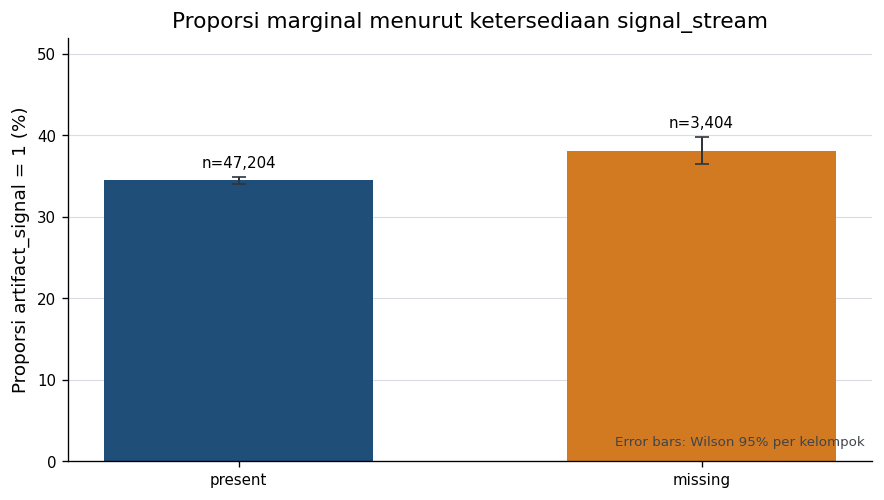

In [5]:
eda_marginal_rows = []
for eda_availability in ('present', 'missing'):
    eda_part = eda_analysis.loc[eda_analysis.availability.eq(eda_availability)]
    eda_successes, eda_n = (int(eda_part.artifact_signal.sum()), int(len(eda_part)))
    eda_low, eda_high = wilson_interval(eda_successes, eda_n)
    eda_marginal_rows.append({'Ketersediaan': eda_availability, 'artifact_signal = 1 (n)': eda_successes, 'Denominator (n)': eda_n, 'Proporsi (%)': 100 * eda_successes / eda_n, 'Wilson 95% bawah (%)': 100 * eda_low, 'Wilson 95% atas (%)': 100 * eda_high})
eda_marginal = pd.DataFrame(eda_marginal_rows)
eda_marginal_indexed = eda_marginal.set_index('Ketersediaan')
eda_marginal_gap_pp = eda_marginal_indexed.loc['missing', 'Proporsi (%)'] - eda_marginal_indexed.loc['present', 'Proporsi (%)']
display(eda_marginal.round(2))
display(Markdown(f"Proporsi artifact pada Train adalah **{eda_marginal_indexed.loc['present', 'Proporsi (%)']:.2f}%** saat stream tersedia dan **{eda_marginal_indexed.loc['missing', 'Proporsi (%)']:.2f}%** saat missing. Selisih missing − present adalah **{eda_marginal_gap_pp:+.2f} poin persentase (pp)**."))
eda_fig, eda_ax = plt.subplots(figsize=(7.5, 4.3))
eda_x = np.arange(len(eda_marginal))
eda_rates = eda_marginal['Proporsi (%)'].to_numpy()
eda_lower = eda_rates - eda_marginal['Wilson 95% bawah (%)'].to_numpy()
eda_upper = eda_marginal['Wilson 95% atas (%)'].to_numpy() - eda_rates
eda_ax.bar(eda_x, eda_rates, color=[eda_COLORS[eda_name] for eda_name in eda_marginal['Ketersediaan']], width=0.58, zorder=2)
eda_ax.errorbar(eda_x, eda_rates, yerr=np.vstack([eda_lower, eda_upper]), fmt='none', ecolor='#30343b', capsize=4, lw=1.2, zorder=3)
for eda_i, eda_row in eda_marginal.iterrows():
    eda_ax.text(eda_i, eda_row['Wilson 95% atas (%)'] + 1.2, f"n={int(eda_row['Denominator (n)']):,}", ha='center', fontsize=9)
eda_ax.set_xticks(eda_x, eda_marginal['Ketersediaan'])
eda_ax.set_ylabel('Proporsi artifact_signal = 1 (%)')
eda_ax.set_title('Proporsi marginal menurut ketersediaan signal_stream')
eda_ax.set_ylim(0, 52)
eda_ax.grid(axis='y', color='#d9dde3', linewidth=0.7, zorder=0)
eda_ax.text(0.99, 0.03, 'Error bars: Wilson 95% per kelompok', transform=eda_ax.transAxes, ha='right', va='bottom', fontsize=8, color='#40444b')
eda_fig.tight_layout()
plt.show()

Label 1 lebih sering muncul pada kelompok kosong, dengan selisih +3,66 pp. Ini belum memperhitungkan perbedaan waktu dan volume laporan.

### EDA 4. Perubahan sepanjang waktu

Selisih kosong dikurangi terisi tidak positif pada semua cycle maupun periode.

,Present n,Present (%),Missing n,Missing (%),Gap missing − present (pp)
period,,,,,
47–57,12537,30.78,1009,28.94,-1.84
58–68,15664,40.37,1072,50.37,10.01
69–79,19003,32.05,1323,35.22,3.18


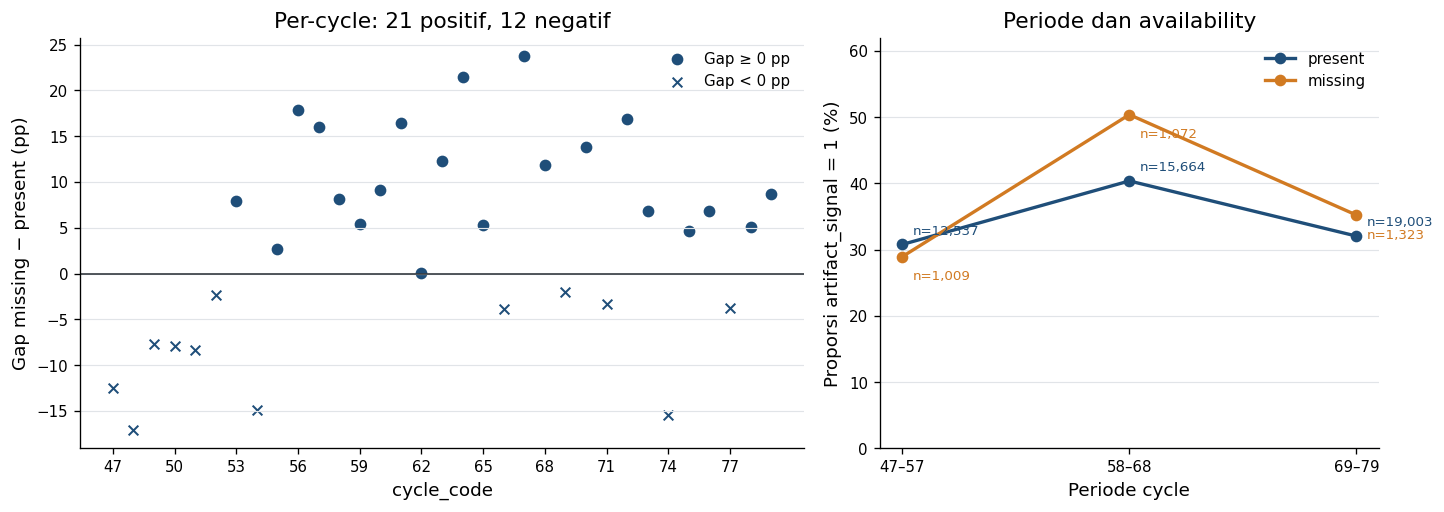

Gap per periode ialah **-1.84 pp**, **+10.01 pp**, dan **+3.18 pp**. Pada cycle dengan n≥20 untuk masing-masing status, 21/33 gap positif dan 12/33 negatif; rentangnya -17.04 sampai +23.73 pp.

In [6]:
eda_period_prevalence = prevalence_table(eda_analysis, ['period', 'availability'])
eda_period_pivot = eda_period_prevalence.pivot(index='period', columns='availability', values='prevalence').loc[['47–57', '58–68', '69–79']]
eda_period_n = eda_period_prevalence.pivot(index='period', columns='availability', values='n').loc[eda_period_pivot.index]
eda_period_summary = pd.DataFrame({'Present n': eda_period_n['present'].astype(int), 'Present (%)': 100 * eda_period_pivot['present'], 'Missing n': eda_period_n['missing'].astype(int), 'Missing (%)': 100 * eda_period_pivot['missing'], 'Gap missing − present (pp)': 100 * (eda_period_pivot['missing'] - eda_period_pivot['present'])})
display(eda_period_summary.round(2))
eda_cycle_prevalence = prevalence_table(eda_analysis, ['cycle_code', 'availability'])
eda_cycle_rates = eda_cycle_prevalence.pivot(index='cycle_code', columns='availability', values='prevalence')
eda_cycle_n = eda_cycle_prevalence.pivot(index='cycle_code', columns='availability', values='n')
eda_cycle_gap = 100 * (eda_cycle_rates['missing'] - eda_cycle_rates['present'])
eda_cycle_supported = eda_cycle_n['missing'].ge(20) & eda_cycle_n['present'].ge(20)
assert eda_cycle_supported.all(), 'Exact-cycle graph must not include unsupported groups'
eda_positive_cycles = int((eda_cycle_gap > 0).sum())
eda_negative_cycles = int((eda_cycle_gap < 0).sum())
eda_fig, (eda_ax_cycle, eda_ax_period) = plt.subplots(1, 2, figsize=(12.2, 4.4), gridspec_kw={'width_ratios': [1.45, 1]})
for eda_marker, eda_condition, eda_label in [('o', eda_cycle_gap >= 0, 'Gap ≥ 0 pp'), ('x', eda_cycle_gap < 0, 'Gap < 0 pp')]:
    eda_ax_cycle.scatter(eda_cycle_gap.index[eda_condition], eda_cycle_gap.loc[eda_condition], marker=eda_marker, s=34, color=eda_COLORS['present'], label=eda_label, linewidths=1.2)
eda_ax_cycle.axhline(0, color='#343a40', lw=1)
eda_ax_cycle.set_xticks(np.arange(47, 80, 3))
eda_ax_cycle.set_xlabel('cycle_code')
eda_ax_cycle.set_ylabel('Gap missing − present (pp)')
eda_ax_cycle.set_title(f'Per-cycle: {eda_positive_cycles} positif, {eda_negative_cycles} negatif')
eda_ax_cycle.legend(frameon=False, loc='best')
eda_ax_cycle.grid(axis='y', color='#e1e4e8', linewidth=0.7)
eda_period_x = np.arange(len(eda_period_pivot))
for eda_availability in ('present', 'missing'):
    eda_values = 100 * eda_period_pivot[eda_availability].to_numpy()
    eda_ax_period.plot(eda_period_x, eda_values, marker='o', lw=2, color=eda_COLORS[eda_availability], label=eda_availability)
    for eda_j, (eda_value, eda_n) in enumerate(zip(eda_values, eda_period_n[eda_availability].to_numpy())):
        eda_offset = (6, 6) if eda_availability == 'present' else (6, -14)
        eda_ax_period.annotate(f'n={int(eda_n):,}', (eda_j, eda_value), xytext=eda_offset, textcoords='offset points', fontsize=8, color=eda_COLORS[eda_availability])
eda_ax_period.set_xticks(eda_period_x, eda_period_pivot.index)
eda_ax_period.set_xlabel('Periode cycle')
eda_ax_period.set_ylabel('Proporsi artifact_signal = 1 (%)')
eda_ax_period.set_title('Periode dan availability')
eda_ax_period.set_ylim(0, 62)
eda_ax_period.legend(frameon=False)
eda_ax_period.grid(axis='y', color='#e1e4e8', linewidth=0.7)
eda_fig.tight_layout()
plt.show()
display(Markdown(f"Gap per periode ialah **{eda_period_summary.iloc[0]['Gap missing − present (pp)']:+.2f} pp**, **{eda_period_summary.iloc[1]['Gap missing − present (pp)']:+.2f} pp**, dan **{eda_period_summary.iloc[2]['Gap missing − present (pp)']:+.2f} pp**. Pada cycle dengan n≥20 untuk masing-masing status, {eda_positive_cycles}/{len(eda_cycle_gap)} gap positif dan {eda_negative_cycles}/{len(eda_cycle_gap)} negatif; rentangnya {eda_cycle_gap.min():+.2f} sampai {eda_cycle_gap.max():+.2f} pp."))

Gap positif pada 21 dari 33 cycle, tetapi negatif pada 12 lainnya. Periode tengah menunjukkan perbedaan terbesar; satu angka agregat menyembunyikan variasi ini.

### EDA 5. Perbedaan volume

Histogram dinormalisasi agar ukuran kelompok yang berbeda tetap dapat dibandingkan. Distribusi volume kedua kelompok berbeda.

,n,minimum,q1,median,q3,maximum
availability,,,,,,
present,47204,20.65,27.70,31.78,36.92,98.06
missing,3404,16.34,20.55,21.81,23.79,77.52


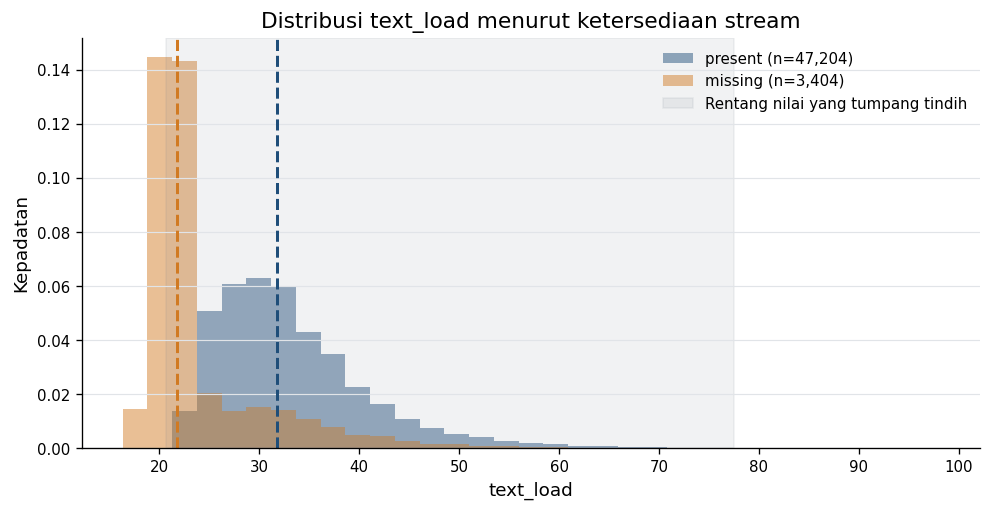

Median text_load adalah **31.78** saat stream tersedia dan **21.81** saat missing. Rentang nilai yang sama-sama teramati adalah **20.65–77.52**; di luarnya terdapat 906 baris missing dan 65 baris present.

In [7]:
eda_text_summary = eda_analysis.groupby('availability')['text_load'].agg(n='size', minimum='min', q1=lambda eda_x: eda_x.quantile(0.25), median='median', q3=lambda eda_x: eda_x.quantile(0.75), maximum='max').loc[['present', 'missing']]
eda_overlap_low = max(eda_text_summary.loc['present', 'minimum'], eda_text_summary.loc['missing', 'minimum'])
eda_overlap_high = min(eda_text_summary.loc['present', 'maximum'], eda_text_summary.loc['missing', 'maximum'])
eda_outside_missing = int((eda_analysis.availability.eq('missing') & ~eda_analysis.text_load.between(eda_overlap_low, eda_overlap_high)).sum())
eda_outside_present = int((eda_analysis.availability.eq('present') & ~eda_analysis.text_load.between(eda_overlap_low, eda_overlap_high)).sum())
display(eda_text_summary.round(2))
eda_fig, eda_ax = plt.subplots(figsize=(8.4, 4.4))
eda_bins = np.linspace(eda_analysis.text_load.min(), eda_analysis.text_load.max(), 34)
for eda_availability in ('present', 'missing'):
    eda_values = eda_analysis.loc[eda_analysis.availability.eq(eda_availability), 'text_load']
    eda_ax.hist(eda_values, bins=eda_bins, density=True, alpha=0.48, color=eda_COLORS[eda_availability], label=f'{eda_availability} (n={len(eda_values):,})')
    eda_ax.axvline(eda_values.median(), color=eda_COLORS[eda_availability], lw=1.8, linestyle='--')
eda_ax.axvspan(eda_overlap_low, eda_overlap_high, color='#78828f', alpha=0.1, label='Rentang nilai yang tumpang tindih')
eda_ax.set_xlabel('text_load')
eda_ax.set_ylabel('Kepadatan')
eda_ax.set_title('Distribusi text_load menurut ketersediaan stream')
eda_ax.legend(frameon=False)
eda_ax.grid(axis='y', color='#e1e4e8', linewidth=0.7)
eda_fig.tight_layout()
plt.show()
display(Markdown(f"Median text_load adalah **{eda_text_summary.loc['present', 'median']:.2f}** saat stream tersedia dan **{eda_text_summary.loc['missing', 'median']:.2f}** saat missing. Rentang nilai yang sama-sama teramati adalah **{eda_overlap_low:.2f}–{eda_overlap_high:.2f}**; di luarnya terdapat {eda_outside_missing:,} baris missing dan {eda_outside_present:,} baris present."))

Median `text_load` kelompok kosong 21,81, sedangkan kelompok terisi 31,78. Komposisi volume yang berbeda menjadi alasan untuk membandingkan kelompok waktu/volume yang lebih setara.

### EDA 6. Menyamakan komposisi

Bandingkan hasil awal dengan penyesuaian setiap cycle serta tiga periode x 5/10 kelompok volume. **Gap = persentase kosong - terisi**, dalam poin persentase (pp). Coverage menunjukkan bagian data yang memenuhi minimum support.

In [8]:
eda_cycle_standardized, eda_cycle_cells = standardized_contrast(eda_analysis, ['cycle_code'], min_support=20)
eda_q5_frame, eda_q5_edges = add_global_quantile_bins(eda_analysis, 5)
eda_period_q5, eda_period_q5_cells = standardized_contrast(eda_q5_frame, ['period', 'text_load_q5'], min_support=20)
eda_q10_frame, eda_q10_edges = add_global_quantile_bins(eda_analysis, 10)
eda_period_q10, eda_period_q10_cells = standardized_contrast(eda_q10_frame, ['period', 'text_load_q10'], min_support=20)
eda_comparison_rows = [{'Kontras': 'Marginal (seluruh Train)', 'Present (%)': eda_marginal_indexed.loc['present', 'Proporsi (%)'], 'Missing (%)': eda_marginal_indexed.loc['missing', 'Proporsi (%)'], 'Gap missing − present (pp)': eda_marginal_gap_pp, 'Sel didukung': '—', 'Baris present tercakup': int(eda_analysis.availability.eq('present').sum()), 'Baris missing tercakup': int(eda_analysis.availability.eq('missing').sum()), 'Coverage keseluruhan (%)': 100.0}]
for eda_label, eda_result in [('Exact cycle', eda_cycle_standardized), ('Periode × kuantil text_load (5)', eda_period_q5), ('Periode × kuantil text_load (10)', eda_period_q10)]:
    eda_comparison_rows.append({'Kontras': eda_label, 'Present (%)': 100 * eda_result['standardized_prevalence']['present'], 'Missing (%)': 100 * eda_result['standardized_prevalence']['missing'], 'Gap missing − present (pp)': eda_result['standardized_missing_minus_present_pp'], 'Sel didukung': f"{eda_result['cells_supported']}/{eda_result['cells_total']}", 'Baris present tercakup': eda_result['covered_rows_by_availability']['present'], 'Baris missing tercakup': eda_result['covered_rows_by_availability']['missing'], 'Coverage keseluruhan (%)': 100 * eda_result['coverage_all_rows']})
eda_contrasts = pd.DataFrame(eda_comparison_rows)
display(eda_contrasts.round(2))
eda_support_by_group = pd.DataFrame([{'Kontras': 'Exact cycle', 'Coverage present (%)': 100 * eda_cycle_standardized['coverage_by_availability']['present'], 'Coverage missing (%)': 100 * eda_cycle_standardized['coverage_by_availability']['missing']}, {'Kontras': 'Periode × kuantil 5', 'Coverage present (%)': 100 * eda_period_q5['coverage_by_availability']['present'], 'Coverage missing (%)': 100 * eda_period_q5['coverage_by_availability']['missing']}, {'Kontras': 'Periode × kuantil 10', 'Coverage present (%)': 100 * eda_period_q10['coverage_by_availability']['present'], 'Coverage missing (%)': 100 * eda_period_q10['coverage_by_availability']['missing']}])
display(eda_support_by_group.round(2))
print(f'Minimum support: 20 baris per availability per sel. Jumlah interval kuantil: 5-bin={len(eda_q5_edges) - 1}; 10-bin={len(eda_q10_edges) - 1}.')

,Kontras,Present (%),Missing (%),Gap missing − present (pp),Sel didukung,Baris present tercakup,Baris missing tercakup,Coverage keseluruhan (%)
0,Marginal (seluruh Train),34.47,38.13,3.66,—,47204,3404,100.00
1,Exact cycle,34.47,38.43,3.96,33/33,47204,3404,100.00
2,Periode × kuantil text_load (5),35.17,32.87,-2.30,15/15,47204,3404,100.00
3,Periode × kuantil text_load (10),35.52,33.36,-2.15,28/30,44368,3372,94.33


,Kontras,Coverage present (%),Coverage missing (%)
0,Exact cycle,100.00,100.00
1,Periode × kuantil 5,100.00,100.00
2,Periode × kuantil 10,93.99,99.06


Minimum support: 20 baris per availability per sel. Jumlah interval kuantil: 5-bin=5; 10-bin=10.


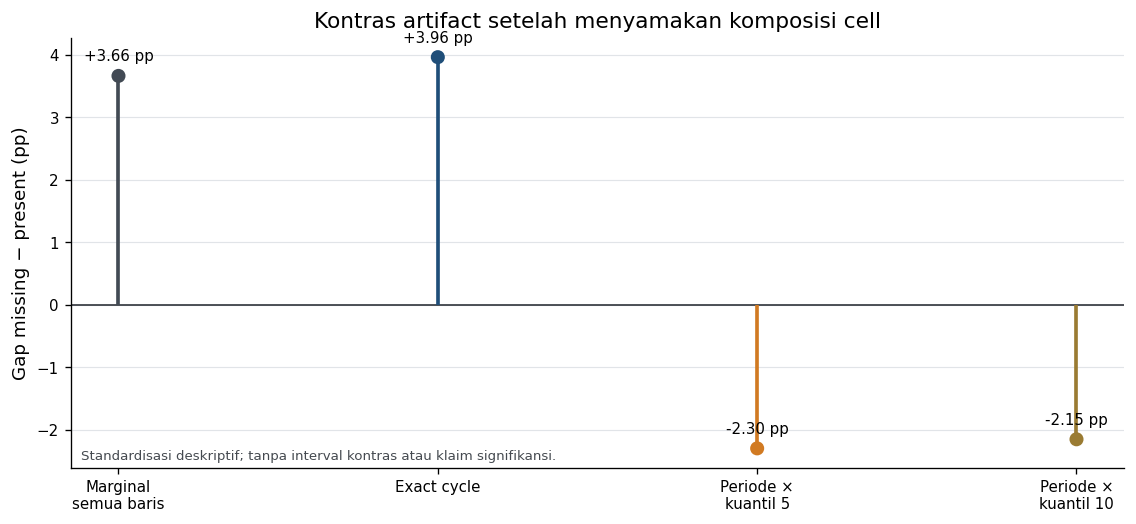

In [9]:
eda_fig, eda_ax = plt.subplots(figsize=(9.6, 4.5))
eda_labels = ['Marginal\nsemua baris', 'Exact cycle', 'Periode ×\nkuantil 5', 'Periode ×\nkuantil 10']
eda_gaps = eda_contrasts['Gap missing − present (pp)'].to_numpy()
eda_colors = ['#424a54', '#1f4e79', '#d17a22', '#9a7b32']
eda_x = np.arange(len(eda_gaps))
eda_ax.axhline(0, color='#30343b', lw=1)
eda_ax.vlines(eda_x, 0, eda_gaps, color=eda_colors, lw=2.2)
eda_ax.scatter(eda_x, eda_gaps, color=eda_colors, s=55, zorder=3)
for eda_i, eda_row in eda_contrasts.iterrows():
    eda_value = eda_row['Gap missing − present (pp)']
    eda_ax.annotate(f'{eda_value:+.2f} pp', (eda_i, eda_value), xytext=(0, 9), textcoords='offset points', ha='center', fontsize=9)
eda_ax.set_xticks(eda_x, eda_labels)
eda_ax.set_ylabel('Gap missing − present (pp)')
eda_ax.set_title('Kontras artifact setelah menyamakan komposisi cell')
eda_ax.grid(axis='y', color='#e1e4e8', linewidth=0.7)
eda_ax.text(0.01, 0.02, 'Standardisasi deskriptif; tanpa interval kontras atau klaim signifikansi.', transform=eda_ax.transAxes, fontsize=8, color='#454a50')
eda_fig.tight_layout()
plt.show()

Menyamakan cycle saja tidak membalik arah gap, sedangkan penyesuaian periode dan volume membalikkannya. Hasil 5 dan 10 kelompok memiliki arah serupa, dengan coverage lebih rendah pada 10 kelompok.

### EDA 7. Interpretasi dan batasan

In [10]:
display(Markdown(
    f"**Hasil:** gap awal {eda_marginal_gap_pp:+.2f} pp; setelah penyesuaian cycle "
    f"{eda_cycle_standardized['standardized_missing_minus_present_pp']:+.2f} pp; "
    f"periode x volume: {eda_period_q5['standardized_missing_minus_present_pp']:+.2f} pp (5 kelompok), "
    f"{eda_period_q10['standardized_missing_minus_present_pp']:+.2f} pp (10 kelompok).\n\n"
    f"**Dukungan:** minimum 20 baris per status/kelompok. Coverage 10 kelompok "
    f"{eda_period_q10['supported_rows_total']:,}/{len(eda_analysis):,} "
    f"({eda_period_q10['coverage_all_rows']:.2%}); "
    f"{eda_period_q10['cells_supported']}/{eda_period_q10['cells_total']} kelompok didukung.\n\n"
    "**Batasan:** kelompok volume masih kasar; faktor lain belum dikontrol. "
    "Hasil bukan sebab-akibat atau konfirmasi independen. Routing berasal dari diagnosis model terdahulu, "
    "bukan ditemukan secara prospektif melalui EDA ini."
))

**Hasil:** gap awal +3.66 pp; setelah penyesuaian cycle +3.96 pp; periode x volume: -2.30 pp (5 kelompok), -2.15 pp (10 kelompok).

**Dukungan:** minimum 20 baris per status/kelompok. Coverage 10 kelompok 47,740/50,608 (94.33%); 28/30 kelompok didukung.

**Batasan:** kelompok volume masih kasar; faktor lain belum dikontrol. Hasil bukan sebab-akibat atau konfirmasi independen. Routing berasal dari diagnosis model terdahulu, bukan ditemukan secara prospektif melalui EDA ini.

### EDA 8. Kesimpulan

Persentase label 1 pada teks kosong lebih tinggi secara keseluruhan (**38,13% vs 34,47%**). Setelah waktu dan volume diperhitungkan, selisih berbalik menjadi sekitar **-2,2 sampai -2,3 pp**. Jadi, perbandingan dipengaruhi komposisi laporan.

Ini hubungan deskriptif, bukan sebab-akibat. Kelompok volume masih kasar; pemeriksaan 10 kelompok mencakup **94,33%** baris. Pola official Test belum diketahui.

## 4. Perkembangan pendekatan

MAE mengukur rata-rata selisih absolut; median menjadi baseline yang sesuai. TP1 memiliki target diskret yang terkonsentrasi, sedangkan TP2 memiliki **34.333 nilai unik**. Karena itu, multiclass per nilai target TP1 tidak disalin.

Tabel berikut adalah hasil historis enam window temporal. Pooled MAE menimbang baris, equal-cycle menimbang cycle. H12 memakai ulang baris primary dan bukan replikasi independen.

In [11]:
r1 = read_report('reports/round1/results.json')
model_names = {'R0_A': 'Global median', 'R0_B': 'Median impact', 'R0_C': 'Median impact × EF',
               'R1_A': 'Standardized OLS', 'R1_B': 'HGB squared error',
               'R1_C': 'HGB dua fitur, MAE', 'R1_D': 'HGB expanded, MAE'}
evolution = pd.DataFrame([{'pendekatan': model_names[k],
                          'primary MAE': r1['aggregate']['primary'][k]['raw']['mae'],
                          'H12 MAE': r1['aggregate']['secondary'][k]['raw']['mae']}
                          for k in model_names])
display(evolution.round(5))
research = pd.DataFrame(read_report('reports/regression_research/report_data.json')['comparison_records'])
selected = research[(research.Policy == 'inner') & research.Recipe.isin(
    ['structured_ridge', 'hybrid_ridge', 'svd_hgb', 'lgb_inner', 'lgb_text'])].copy()
display(selected[['Recipe', 'Primary MAE', 'Equal-cycle MAE', 'H12 MAE', 'H12_E', 'H12_L']].round(5))
# Committed aggregates only; this cell never opens experiment caches.
provenance_paths = ['reports/round1/results.json', 'reports/regression_round2/results.json',
                    'reports/regression_research/report_data.json', 'reports/regression_research/stage5_lgb_text.json']
provenance = {p: sha(ROOT/p) for p in provenance_paths}
print('Sumber tabel historis:', ', '.join(provenance_paths))

,pendekatan,primary MAE,H12 MAE
0,Global median,24.99995,24.99995
1,Median impact,15.56157,15.94048
2,Median impact × EF,15.31140,15.67423
3,Standardized OLS,15.62263,15.83498
4,HGB squared error,15.57102,15.89889
5,"HGB dua fitur, MAE",15.14899,15.47789
6,"HGB expanded, MAE",13.34984,15.57724


,Recipe,Primary MAE,Equal-cycle MAE,H12 MAE,H12_E,H12_L
31,hybrid_ridge,12.55130,12.79007,13.93812,16.39546,11.85908
35,svd_hgb,12.36618,12.67774,14.71412,17.27256,12.54955
39,lgb_inner,13.06489,13.32251,15.60415,17.88659,13.67310
45,structured_ridge,14.17865,14.33300,15.20582,17.22924,13.49390
47,lgb_text,11.93160,12.28355,14.70404,17.47326,12.36114


Sumber tabel historis: reports/round1/results.json, reports/regression_round2/results.json, reports/regression_research/report_data.json, reports/regression_research/stage5_lgb_text.json


Global median menghasilkan MAE **25,0000**. Median menurut impact dan entry friction menurunkannya menjadi **15,3114**, menunjukkan bahwa informasi fitur memberi baseline yang jauh lebih baik. HGB dua fitur dengan objective MAE mencapai **15,1490**; fitur structured yang diperluas mencapai **13,3498** pada primary.

Perluasan fitur belum selalu membantu: H12 HGB meningkat dari **15,4779 menjadi 15,5772**, yaitu memburuk. Karena recency dan penghapusan fitur juga tidak konsisten, langkah berikutnya menambahkan informasi teks. Structured Ridge **14,1787** menjadi hybrid Ridge **12,5513** pada primary; perbandingan satu keluarga ini mendukung manfaat prediktif teks.

HGB+SVD mencapai **12,3662**, lalu LightGBM+SVD memberi primary terbaik **11,9316**. Namun hybrid Ridge tetap lebih baik pada H12 (**13,9381 vs 14,7040**). LightGBM dipilih dengan menerima trade-off horizon tersebut, bukan karena unggul pada setiap kondisi.

,window,MAE,n
0,W1,16.40578,4114
1,W2,12.04287,6493
2,W3,12.35421,7078
3,W4,11.99939,4950
4,W5,10.77491,7462
5,W6,10.30343,8491
6,H12_E,17.47326,17685
7,H12_L,12.36114,20903


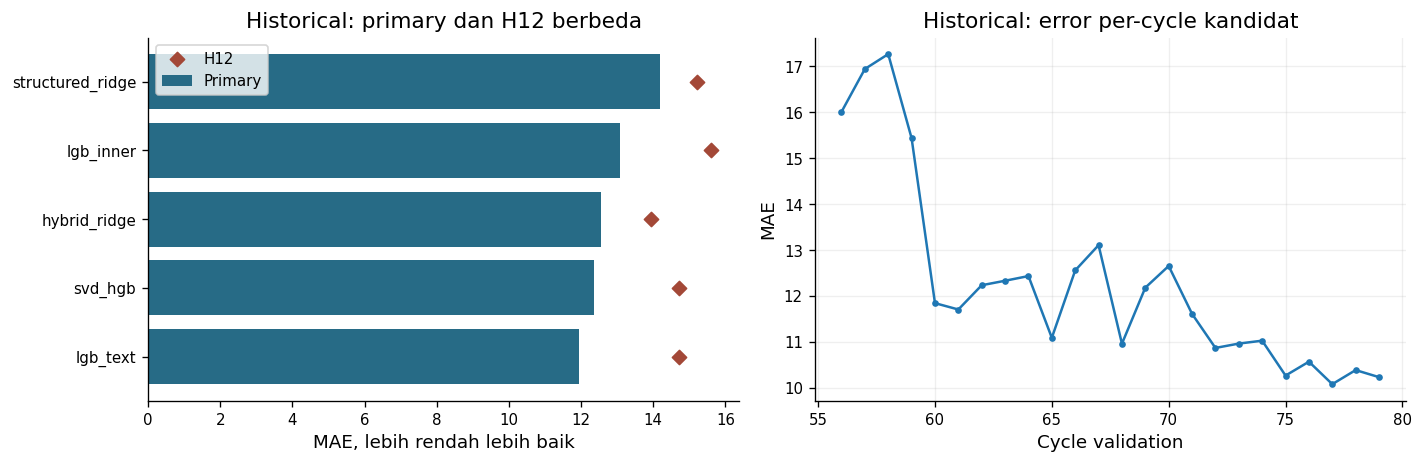

In [12]:
stage5 = read_report('reports/regression_research/stage5_lgb_text.json')
window_rows = []
for j in stage5['jobs']:
    if j['policy'] == 'inner':
        window_rows.append({'window': j['window'], 'MAE': j['raw']['mae'], 'n': j['raw']['n']})
windows = pd.DataFrame(window_rows)
display(windows.round(5))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
order = selected.sort_values('Primary MAE')
axes[0].barh(order.Recipe, order['Primary MAE'], color='#276b86', label='Primary')
axes[0].scatter(order['H12 MAE'], order.Recipe, color='#a34837', marker='D', label='H12')
axes[0].set(title='Historical: primary dan H12 berbeda', xlabel='MAE, lebih rendah lebih baik'); axes[0].legend()
pc = pd.DataFrame(stage5['aggregate']['primary']['lgb_text__inner']['per_cycle'])
axes[1].plot(pc.cycle, pc.mae, '-o', markersize=3)
axes[1].set(title='Historical: error per-cycle kandidat', xlabel='Cycle validation', ylabel='MAE')
axes[1].grid(alpha=.2); fig.tight_layout(); plt.show()

## 5. Pipeline dan validasi

1. Parser numerik; imputasi median dan encoding kategori dari fit fold. Unknown category -1 diperlakukan LightGBM sebagai missing.
2. TF-IDF unigram-bigram, maksimal 20.000 fitur, `min_df=2`; SVD32 (`n_iter=7`, seed 42).
3. LightGBM `regression_l1`, 400 trees, learning rate 0,05; dua konfigurasi frozen: base (31 leaves/minleaf40/L2=1), regularized (15/80/3).
4. Inner MAE memilih konfigurasi dan alpha dari {0; 0,25; 0,50; 0,75; 1}.

Rank blend: `clip((1-alpha)*raw + alpha*100*average_rank(raw)/n_cycle, 0, 100)`. Rank berasal dari prediksi, bukan label; baris dalam satu cycle harus diprediksi bersama. Mapping mengubah jarak, bukan urutan prediksi.

**Inner:** 47-71 -> 72-75. **Outer:** refit 47-75 -> evaluasi 76-79. Semua preprocessing dibangun ulang per fit.

In [13]:
def rank_blend(raw, cycles, weight):
    frame = pd.DataFrame({'p': np.asarray(raw, float), 'c': np.asarray(cycles)})
    if not np.isfinite(frame.p).all() or frame.c.isna().any():
        raise ValueError('Prediksi dan cycle harus finite/lengkap.')
    percentile = (100 * frame.groupby('c').p.rank(method='average') /
                  frame.groupby('c').p.transform('size')).to_numpy()
    return np.clip((1-weight)*frame.p.to_numpy() + weight*percentile, 0, 100)

def fit_predict(params_id, fit_frame, predict_frame):
    model = build_lgb_text(params_id)
    with threadpool_limits(limits=2):
        model.fit(fit_frame[features], fit_frame.threat_rank.to_numpy())
        raw = model.predict(predict_frame[features])
    assert model.audit_state()['fit_rows'] == len(fit_frame)
    return model, raw

inner_train = train[train.cycle_code <= 71].copy()
inner_valid = train[train.cycle_code.between(72, 75)].copy()
outer_train = train[train.cycle_code <= 75].copy()
outer_valid = train[train.cycle_code.between(76, 79)].copy()
assert inner_train.cycle_code.max() < inner_valid.cycle_code.min()
assert outer_train.cycle_code.max() < outer_valid.cycle_code.min()
assert not set(outer_train.record_id) & set(outer_valid.record_id)
choices = []
start = time.perf_counter()
for param in ['base', 'regularized']:
    _, raw = fit_predict(param, inner_train, inner_valid)
    for alpha in [0., .25, .5, .75, 1.]:
        mapped = rank_blend(raw, inner_valid.cycle_code, alpha)
        choices.append({'param': param, 'rank_weight': alpha,
                        'MAE inner': mean_absolute_error(inner_valid.threat_rank, mapped)})
inner_choices = pd.DataFrame(choices).sort_values(['MAE inner', 'param', 'rank_weight'], kind='stable')
chosen = inner_choices.iloc[0]
display(inner_choices.reset_index(drop=True).round(6))
print('Keputusan W6 hanya dari inner:', chosen.param, float(chosen.rank_weight))

,param,rank_weight,MAE inner
0,base,0.50,10.73005
1,base,0.25,10.77491
2,base,0.75,10.77497
3,base,0.00,10.89544
4,base,1.00,10.91451
5,regularized,0.50,11.11519
6,regularized,0.25,11.15319
7,regularized,0.75,11.16510
8,regularized,0.00,11.27684
9,regularized,1.00,11.31529


Keputusan W6 hanya dari inner: base 0.5


In [14]:
outer_model, outer_raw = fit_predict(chosen.param, outer_train, outer_valid)
outer_prediction = rank_blend(outer_raw, outer_valid.cycle_code, float(chosen.rank_weight))
y_outer = outer_valid.threat_rank.to_numpy()
baseline_models = [
    {'id':'R0_A','kind':'global_median','features':'two'},
    {'id':'R0_C','kind':'joint_median','features':'two'}]
baseline_rows = []
for recipe in baseline_models:
    baseline = build_round1_model(recipe)
    names = [] if recipe['kind']=='global_median' else ['impact_load','entry_friction']
    with threadpool_limits(limits=2):
        baseline.fit(outer_train[names], outer_train.threat_rank.to_numpy())
        baseline_pred = baseline.predict(outer_valid[names])
    baseline_rows.append({'recipe':recipe['id'],'MAE W6':mean_absolute_error(y_outer,baseline_pred)})
display(pd.DataFrame(baseline_rows).round(5))
error = outer_prediction - y_outer
w6_metrics = {'n': len(y_outer), 'MAE': float(np.abs(error).mean()),
              'RMSE': float(np.sqrt(np.mean(error**2))), 'bias pred-actual': float(error.mean())}
expected_w6 = next(j for j in stage5['jobs'] if j['window'] == 'W6' and j['policy'] == 'inner')
assert np.isclose(w6_metrics['MAE'], expected_w6['raw']['mae'], rtol=0, atol=1e-8), 'Reproduksi W6 berbeda; selidiki environment/input.'
assert array_digest(outer_prediction) == expected_w6['prediction_sha256']
display(pd.DataFrame([w6_metrics], index=['Dihitung ulang: W6 76–79']))
core_receipt = {'task':'regression','fit_cycles':[47,75],'validation_cycles':[76,79],
    'fit_rows':len(outer_train),'validation_rows':len(outer_valid),'inner_choice':{
        'param':str(chosen.param),'rank_weight':float(chosen.rank_weight)},
    'metrics':w6_metrics,'prediction_sha256':array_digest(outer_prediction),
    'matches_historical_predictions':True,'historical_primary_mae':11.931600241417073,
    'historical_h12_mae':14.704040710404005,'kaggle_public_mae':11.71363,
    'fit_preprocessing_only_train':True,'test_used_in_core':False,'baseline_metrics':baseline_rows}
receipt_path = ROOT/'artifacts/samuel_eda_final_review/regression_core_receipt.json'
receipt_path.parent.mkdir(parents=True,exist_ok=True)
receipt_path.write_text(json.dumps(core_receipt,indent=2)+'\n',encoding='utf-8')
w6_by_cycle = pd.DataFrame({'cycle': outer_valid.cycle_code.to_numpy(), 'abs_error': abs(error)}).groupby('cycle').agg(n=('abs_error','size'), MAE=('abs_error','mean'))
display(w6_by_cycle)
print('Equal-cycle W6:', w6_by_cycle.MAE.mean(), '| total detik training demonstrasi:', round(time.perf_counter()-start, 1))

,recipe,MAE W6
0,R0_A,25.00000
1,R0_C,14.96965


,n,MAE,RMSE,bias pred-actual
Dihitung ulang: W6 76–79,8491,10.30343,14.19391,-0.46194


,n,MAE
cycle,,
76,1822,10.57096
77,2335,10.08157
78,2146,10.38822
79,2188,10.23424


Equal-cycle W6: 10.31874648947231 | total detik training demonstrasi: 42.0


## 6. Evaluasi model

W6 dihitung ulang di atas; angka primary/H12 berasal dari eksperimen historis. LightGBM+text memberi **MAE 11,93160 primary / 14,70404 H12**. Namun **hybrid Ridge lebih baik pada H12: 13,93812**. Model terpilih tidak mendominasi semua horizon.

Seluruh window sudah digunakan dalam development; reproduksi W6 bukan holdout baru.

Hasil primary yang lebih baik belum berarti unggul pada semua horizon. Keunggulan Ridge di H12 menjadi alasan untuk tetap menampilkannya sebagai pembanding.

,kelompok,n,MAE W6,bias W6
0,Semua,8491,10.30343,-0.46194
1,EF0,5738,11.49037,-1.12429
2,EF1,2753,7.82950,0.91857
3,Target ≤5,442,8.44707,8.17898
4,Target ≥95,434,5.97580,-5.34055
5,Stream missing,526,12.88477,3.97574
6,Stream present,7965,10.13296,-0.75500


,Recipe,Primary MAE,EF0,EF1,Low tail,High tail,Missing,Present
31,hybrid_ridge,12.5513,13.76768,10.02465,10.83168,9.55167,14.36961,12.42113
47,lgb_text,11.9316,12.97905,9.75585,12.23539,9.49544,13.04181,11.85212


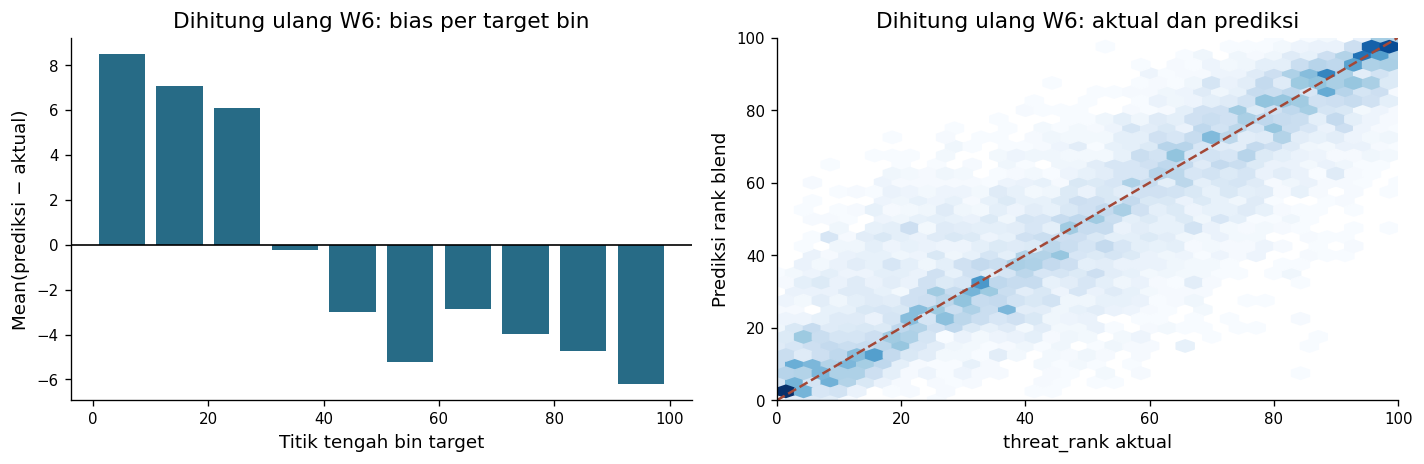

In [15]:
masks = {'Semua': np.ones(len(outer_valid), bool),
         'EF0': outer_valid.entry_friction.eq(0).to_numpy(),
         'EF1': outer_valid.entry_friction.eq(1).to_numpy(),
         'Target ≤5': y_outer <= 5, 'Target ≥95': y_outer >= 95,
         'Stream missing': stream_missing_mask(outer_valid),
         'Stream present': ~stream_missing_mask(outer_valid)}
fresh_subgroups = pd.DataFrame([{'kelompok': name, 'n': int(mask.sum()),
      'MAE W6': float(abs(error[mask]).mean()) if mask.any() else np.nan,
      'bias W6': float(error[mask].mean()) if mask.any() else np.nan}
      for name, mask in masks.items()])
display(fresh_subgroups.round(5))
display(selected[selected.Recipe.isin(['hybrid_ridge', 'lgb_text'])][
    ['Recipe', 'Primary MAE', 'EF0', 'EF1', 'Low tail', 'High tail', 'Missing', 'Present']].round(5))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
bins = pd.cut(y_outer, np.arange(0, 101, 10), include_lowest=True)
grouped = pd.DataFrame({'bin': bins, 'err': error}).groupby('bin', observed=True).err.mean()
axes[0].bar(np.arange(len(grouped))*10+5, grouped, width=8, color='#276b86')
axes[0].axhline(0, color='black', lw=1)
axes[0].set(title='Dihitung ulang W6: bias per target bin', xlabel='Titik tengah bin target', ylabel='Mean(prediksi − aktual)')
axes[1].hexbin(y_outer, outer_prediction, gridsize=35, mincnt=1, cmap='Blues')
axes[1].plot([0,100], [0,100], '--', color='#a34837')
axes[1].set(title='Dihitung ulang W6: aktual dan prediksi', xlabel='threat_rank aktual', ylabel='Prediksi rank blend', xlim=(0,100), ylim=(0,100))
fig.tight_layout(); plt.show()

Pada grafik bias, target rendah cenderung diprediksi terlalu tinggi dan target tinggi terlalu rendah. Prediksi mendekati nilai tengah dapat memberi MAE yang baik secara keseluruhan, tetapi masih kurang tepat pada target ekstrem.

Sebagian Test memiliki nilai count nol tanpa analog Train; maknanya belum diketahui. Tanpa label Test, risikonya belum dapat diukur. Banyaknya eksperimen juga membatasi kekuatan kesimpulan generalisasi.

## 7. Melatih model akhir dan membuat prediksi Test

Evaluasi sebelumnya memisahkan data masa lalu untuk melatih model dan cycle berikutnya untuk mengukur error. Setelah pendekatan dipilih, model dilatih ulang memakai **seluruh 50.608 baris Train**, agar prediksi official Test memanfaatkan semua label yang tersedia. Tahap inilah yang disebut **refit penuh**.

Sel di bawah menjalankannya jika `RUN_FULL_TRAIN = True`: seluruh preprocessing dipelajari ulang dari Train, kemudian model memprediksi Test dan menyimpan CSV lokal. Nilainya dibiarkan `False` saat demonstrasi agar tidak mengulang pembuatan file; **evaluasi temporal di bagian sebelumnya tetap dijalankan**.

Tahap ini tidak menghasilkan skor validasi baru karena label Test tidak tersedia. Angka public Kaggle yang ditampilkan berasal dari submission historis, bukan dihitung oleh sel ini.

In [16]:
RUN_FULL_TRAIN = False
if RUN_FULL_TRAIN:
    assert files['test'] and files['sample'], 'Official Test dan SampleSubmission diperlukan untuk inference.'
    assert sha(files['test']) == '4e6c381d582ed24f92d17f620f4f0ad25e2e0def29eb57a91a5482867f6afe3c'
    assert sha(files['sample']) == '63a51f4b7dfbb0eec9800099407abd8be14d25ec18a533cd39dc854ffc190a32'
    test = pd.read_csv(files['test']); sample = pd.read_csv(files['sample'])
    assert test.shape == (29421, 18) and 'threat_rank' not in test
    assert set(test.columns) == set(train.columns) - {'threat_rank'}
    assert test.record_id.is_unique and not set(train.record_id) & set(test.record_id)
    assert test.cycle_code.between(80, 91).all()
    assert sample.columns.tolist() == ['record_id','threat_rank'] and sample.record_id.equals(test.record_id)
    deployment_choices = []
    for param in ['base', 'regularized']:
        if param == chosen.param:
            raw = outer_raw
        else:
            _, raw = fit_predict(param, outer_train, outer_valid)
        for alpha in [0., .25, .5, .75, 1.]:
            p = rank_blend(raw, outer_valid.cycle_code, alpha)
            deployment_choices.append({'param': param, 'alpha': alpha,
                'mae': mean_absolute_error(y_outer, p)})
    deployment = sorted(deployment_choices, key=lambda d: (d['mae'], d['param'], d['alpha']))[0]
    assert deployment['param'] == 'base' and deployment['alpha'] == .5
    final_model, test_raw = fit_predict(deployment['param'], train, test)
    test_prediction = rank_blend(test_raw, test.cycle_code, deployment['alpha'])
    output = sample.copy()
    output['threat_rank'] = test_prediction
    assert len(output) == 29421 and output.record_id.is_unique
    assert output.record_id.equals(test.record_id) and np.isfinite(test_prediction).all()
    assert output.threat_rank.between(0, 100).all()
    destination = ROOT / 'artifacts/samuel_eda_final_review/regression_reproduced.csv'
    destination.parent.mkdir(parents=True, exist_ok=True)
    csv_bytes = output.to_csv(index=False, float_format='%.17g').encode('utf-8')
    if destination.exists() and destination.read_bytes() != csv_bytes:
        raise FileExistsError('Output sebelumnya berbeda; periksa sebelum mengganti file.')
    destination.write_bytes(csv_bytes)
    print('Refit:', final_model.audit_state()['fit_rows'], 'baris | CSV:', len(output), 'baris')
    print('Deployment:', deployment, '| SHA-256:', sha(destination))
    print('CSV lokal siap diperiksa; tidak ada upload otomatis.')
else:
    print('Refit/inference final belum dijalankan pada eksekusi ini. Aktifkan RUN_FULL_TRAIN jika diperlukan.')

Refit/inference final belum dijalankan pada eksekusi ini. Aktifkan RUN_FULL_TRAIN jika diperlukan.


## 8. Kesimpulan

EDA menunjukkan bahwa perbandingan proporsi artifact pada teks kosong dan terisi dipengaruhi waktu serta volume laporan. Gap awal **+3,66 pp** berubah menjadi sekitar **-2,2 sampai -2,3 pp** setelah penyesuaian. Analisis ini memakai target Classification; manfaat teks untuk prediksi `threat_rank` harus dinilai melalui eksperimen Regression tersendiri.

Dalam eksperimen Regression, fitur structured memperbaiki baseline median, kemudian tambahan teks kembali menurunkan MAE. LightGBM L1 dengan TF-IDF/SVD32 dan inner-selected rank blend dipilih karena mencapai **primary MAE 11,9316**. Rank blend menyesuaikan jarak prediksi dalam setiap cycle tanpa menggunakan label inference.

Pilihan tersebut memiliki trade-off. H12 LightGBM adalah **14,7040**, sedangkan hybrid Ridge lebih baik pada **13,9381**. Prediksi juga masih terlalu tinggi pada target rendah dan terlalu rendah pada target tinggi. Karena itu, rata-rata MAE yang baik belum berarti error sudah merata pada semua horizon dan kelompok target.

Public benchmark approach individual ini adalah **11,71363**, terpisah dari validasi internal. Seluruh window telah digunakan dalam development, dan label Test belum tersedia; hasil tidak menjamin private generalization. EDA dan evaluasi model bersama-sama membantu menjelaskan data, alasan pemilihan pendekatan, serta keterbatasan keputusan tersebut.